<a href="https://colab.research.google.com/github/Ewanjohndennis/ML_LAB/blob/main/assignment12.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Assignment 12 — Week 2 October

## Learning Objective

To understand bootstrapping, cross-validation, and the bias-variance tradeoff.

### 1. Classification of Iris Flowers Using K-Fold Cross-Validation

**Problem Statement:**

The Iris dataset contains measurements of flowers belonging to three species: Iris setosa, Iris versicolor, and Iris virginica. Each sample has four features: sepal length, sepal width, petal length, and petal width.

The objective is to classify iris flowers using a machine learning algorithm and evaluate its performance using 5-fold and 10-fold cross-validation.

**Tasks:**

1. Load the Iris dataset using Scikit-learn.
2. Display the number of samples, features, feature names, target names, and class distribution.
3. Separate the features into X and target labels into y.
4. Train a suitable classifier.
5. Evaluate the classifier using 5-fold cross-validation.
6. Display the accuracy for each fold, mean accuracy, and standard deviation.
7. Repeat the experiment using 10-fold cross-validation.
8. Compare the results of both methods.
9. Generate a confusion matrix using cross-validated predictions.
10. Display a classification report containing precision, recall, and F1-score.

Number of samples: 150
Number of features: 4
Feature names: ['sepal length (cm)', 'sepal width (cm)', 'petal length (cm)', 'petal width (cm)']
Target names: ['setosa' 'versicolor' 'virginica']
Class distribution: [50 50 50]

5-Fold Accuracies: [1.         1.         0.96666667 0.93333333 0.96666667]
Mean Accuracy: 0.9733333333333334
Standard Deviation: 0.024944382578492935

10-Fold Accuracies: [1.         1.         1.         1.         1.         0.93333333
 0.86666667 1.         1.         0.93333333]
Mean Accuracy: 0.9733333333333334
Standard Deviation: 0.04422166387140532

Comparison:
5-Fold Mean Accuracy: 0.9733333333333334
10-Fold Mean Accuracy: 0.9733333333333334


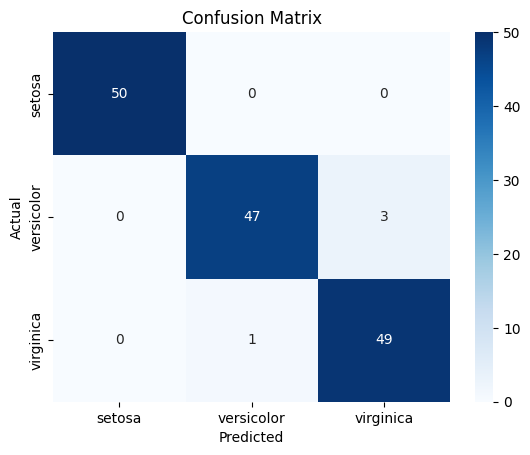

              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        50
  versicolor       0.98      0.94      0.96        50
   virginica       0.94      0.98      0.96        50

    accuracy                           0.97       150
   macro avg       0.97      0.97      0.97       150
weighted avg       0.97      0.97      0.97       150



In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.datasets import load_iris
from sklearn.neighbors import KNeighborsClassifier
from sklearn.model_selection import KFold, cross_val_score, cross_val_predict
from sklearn.metrics import confusion_matrix, classification_report

iris = load_iris()
X = iris.data
y = iris.target

print("Number of samples:", X.shape[0])
print("Number of features:", X.shape[1])
print("Feature names:", iris.feature_names)
print("Target names:", iris.target_names)
print("Class distribution:", pd.Series(y).value_counts().sort_index().values)

model = KNeighborsClassifier(n_neighbors=5)

kf5 = KFold(n_splits=5, shuffle=True, random_state=42)
scores5 = cross_val_score(model, X, y, cv=kf5)

print("\n5-Fold Accuracies:", scores5)
print("Mean Accuracy:", scores5.mean())
print("Standard Deviation:", scores5.std())

kf10 = KFold(n_splits=10, shuffle=True, random_state=42)
scores10 = cross_val_score(model, X, y, cv=kf10)

print("\n10-Fold Accuracies:", scores10)
print("Mean Accuracy:", scores10.mean())
print("Standard Deviation:", scores10.std())

print("\nComparison:")
print("5-Fold Mean Accuracy:", scores5.mean())
print("10-Fold Mean Accuracy:", scores10.mean())

y_pred = cross_val_predict(model, X, y, cv=kf5)

cm = confusion_matrix(y, y_pred)

sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=iris.target_names,
            yticklabels=iris.target_names)
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Confusion Matrix")
plt.show()

print(classification_report(y, y_pred, target_names=iris.target_names))

### 2. Bootstrap Sampling and Model Evaluation Using the Iris Dataset

**Problem Statement:**

Bootstrap sampling is a resampling technique in which samples are repeatedly drawn with replacement from the original dataset. This experiment evaluates a classifier using bootstrap samples and out-of-bag observations.

**Tasks:**

1. Load the Iris dataset and display its first five samples.
2. Select petal length as the input feature and iris species as the target.
3. Generate 100 bootstrap samples, each containing 150 observations.
4. Train a classifier on each bootstrap sample.
5. Evaluate the classifier using out-of-bag observations.
6. Calculate the mean, standard deviation, minimum, and maximum accuracy.
7. Plot a histogram of bootstrap accuracies.
8. Calculate a 95% percentile confidence interval.
9. Compare bootstrap performance with an 80:20 train-test split.

   sepal length (cm)  sepal width (cm)  petal length (cm)  petal width (cm)  \
0                5.1               3.5                1.4               0.2   
1                4.9               3.0                1.4               0.2   
2                4.7               3.2                1.3               0.2   
3                4.6               3.1                1.5               0.2   
4                5.0               3.6                1.4               0.2   

   Species  
0        0  
1        0  
2        0  
3        0  
4        0  

Mean Accuracy: 0.9346044962164194
Standard Deviation: 0.031805998693342045
Minimum Accuracy: 0.847457627118644
Maximum Accuracy: 1.0


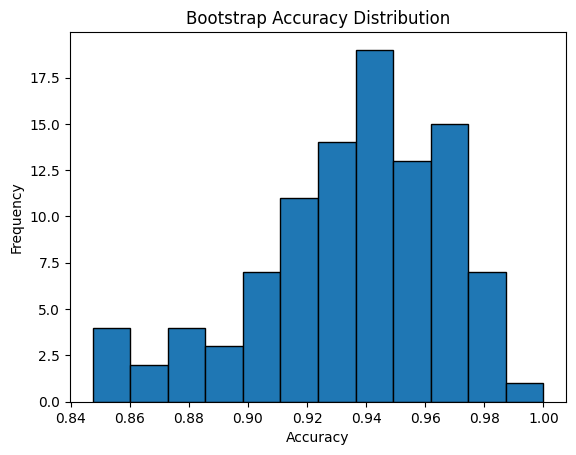

95% Confidence Interval: [0.85712366 0.98165825]
80:20 Split Accuracy: 0.9333333333333333
Bootstrap Mean Accuracy: 0.9346044962164194


In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.datasets import load_iris
from sklearn.neighbors import KNeighborsClassifier
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score

iris = load_iris()

df = pd.DataFrame(iris.data, columns=iris.feature_names)
df['Species'] = iris.target

print(df.head())

X = iris.data[:, [2]]
y = iris.target

np.random.seed(42)
accuracies = []

for i in range(100):
    indices = np.random.choice(len(X), len(X), replace=True)
    oob = np.setdiff1d(np.arange(len(X)), np.unique(indices))

    if len(oob) == 0:
        continue

    model = KNeighborsClassifier(n_neighbors=5)
    model.fit(X[indices], y[indices])

    pred = model.predict(X[oob])
    accuracies.append(accuracy_score(y[oob], pred))

accuracies = np.array(accuracies)

print("\nMean Accuracy:", accuracies.mean())
print("Standard Deviation:", accuracies.std())
print("Minimum Accuracy:", accuracies.min())
print("Maximum Accuracy:", accuracies.max())

plt.hist(accuracies, bins=12, edgecolor='black')
plt.xlabel("Accuracy")
plt.ylabel("Frequency")
plt.title("Bootstrap Accuracy Distribution")
plt.show()

print("95% Confidence Interval:",
      np.percentile(accuracies, [2.5, 97.5]))

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

model = KNeighborsClassifier(n_neighbors=5)
model.fit(X_train, y_train)

pred = model.predict(X_test)

print("80:20 Split Accuracy:", accuracy_score(y_test, pred))
print("Bootstrap Mean Accuracy:", accuracies.mean())

### 3. Comparison of Bootstrapping and Cross-Validation

**Problem Statement:**

Bootstrapping and cross-validation are resampling techniques used to estimate the performance of machine learning models. This experiment compares their performance metrics using the Iris dataset.

**Tasks:**

1. Load and preprocess the Iris dataset.
2. Implement bootstrap sampling and evaluate the model.
3. Implement k-fold cross-validation.
4. Compare accuracy, precision, recall, and F1-score.
5. Discuss the advantages and disadvantages of both methods.

In [5]:
import numpy as np
import pandas as pd
from sklearn.datasets import load_iris
from sklearn.neighbors import KNeighborsClassifier
from sklearn.model_selection import KFold, cross_validate
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

iris = load_iris()
X = iris.data
y = iris.target

model = KNeighborsClassifier(n_neighbors=5)

scoring = {
    'accuracy': 'accuracy',
    'precision': 'precision_macro',
    'recall': 'recall_macro',
    'f1': 'f1_macro'
}

kf = KFold(n_splits=5, shuffle=True, random_state=42)
cv = cross_validate(model, X, y, cv=kf, scoring=scoring)

cv_results = {
    'Accuracy': cv['test_accuracy'].mean(),
    'Precision': cv['test_precision'].mean(),
    'Recall': cv['test_recall'].mean(),
    'F1-Score': cv['test_f1'].mean()
}

np.random.seed(42)

bootstrap_results = {
    'Accuracy': [],
    'Precision': [],
    'Recall': [],
    'F1-Score': []
}

for i in range(100):
    indices = np.random.choice(len(X), len(X), replace=True)
    oob = np.setdiff1d(np.arange(len(X)), np.unique(indices))

    if len(oob) == 0:
        continue

    model = KNeighborsClassifier(n_neighbors=5)
    model.fit(X[indices], y[indices])
    pred = model.predict(X[oob])

    bootstrap_results['Accuracy'].append(accuracy_score(y[oob], pred))
    bootstrap_results['Precision'].append(
        precision_score(y[oob], pred, average='macro', zero_division=0)
    )
    bootstrap_results['Recall'].append(
        recall_score(y[oob], pred, average='macro', zero_division=0)
    )
    bootstrap_results['F1-Score'].append(
        f1_score(y[oob], pred, average='macro', zero_division=0)
    )

bootstrap_results = {
    key: np.mean(value) for key, value in bootstrap_results.items()
}

comparison = pd.DataFrame({
    'Metric': cv_results.keys(),
    'Bootstrap': bootstrap_results.values(),
    '5-Fold Cross-Validation': cv_results.values()
})

print(comparison.round(4).to_string(index=False))

   Metric  Bootstrap  5-Fold Cross-Validation
 Accuracy     0.9553                   0.9733
Precision     0.9564                   0.9775
   Recall     0.9567                   0.9744
 F1-Score     0.9551                   0.9742


### 4. Investigating the Bias-Variance Tradeoff Using Polynomial Regression

**Problem Statement:**

The bias-variance tradeoff describes the balance between underfitting and overfitting in machine learning models. Polynomial regression can demonstrate this tradeoff by varying the polynomial degree.

**Tasks:**

1. Load the Boston Housing dataset and preprocess it.
2. Fit polynomial regression models with different degrees.
3. Calculate training and validation errors for each degree.
4. Plot the training and validation errors.
5. Discuss how polynomial degree affects bias, variance, and generalization performance.

Degree 1: Training MSE = 42.9966, Validation MSE = 46.1448
Degree 2: Training MSE = 38.9079, Validation MSE = 35.3698
Degree 3: Training MSE = 37.7344, Validation MSE = 34.4452
Degree 4: Training MSE = 35.8886, Validation MSE = 39.5780
Degree 5: Training MSE = 35.1459, Validation MSE = 32.5148
Degree 6: Training MSE = 34.9966, Validation MSE = 35.6278
Degree 7: Training MSE = 34.9829, Validation MSE = 38.8950
Degree 8: Training MSE = 34.9664, Validation MSE = 34.6971
Degree 9: Training MSE = 34.3582, Validation MSE = 235.7822
Degree 10: Training MSE = 34.1583, Validation MSE = 33.7514


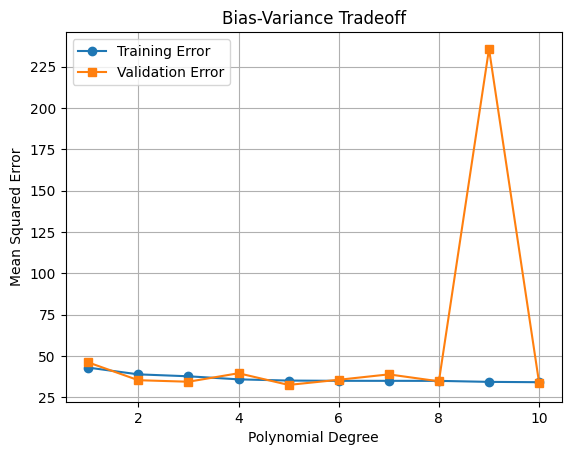

Best Polynomial Degree: 5
Lowest Validation MSE: 32.5147511722509


In [6]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import fetch_openml
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, PolynomialFeatures
from sklearn.linear_model import LinearRegression
from sklearn.pipeline import make_pipeline
from sklearn.metrics import mean_squared_error

housing = fetch_openml(name='boston', version=1, as_frame=True)

X = housing.data[['RM']].astype(float)
y = housing.target.astype(float)

X_train, X_val, y_train, y_val = train_test_split(
    X, y, test_size=0.2, random_state=42
)

scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_val = scaler.transform(X_val)

degrees = range(1, 11)
train_errors = []
val_errors = []

for degree in degrees:
    model = make_pipeline(
        PolynomialFeatures(degree),
        LinearRegression()
    )

    model.fit(X_train, y_train)

    train_pred = model.predict(X_train)
    val_pred = model.predict(X_val)

    train_errors.append(mean_squared_error(y_train, train_pred))
    val_errors.append(mean_squared_error(y_val, val_pred))

    print(
        f"Degree {degree}: "
        f"Training MSE = {train_errors[-1]:.4f}, "
        f"Validation MSE = {val_errors[-1]:.4f}"
    )

plt.plot(degrees, train_errors, marker='o', label='Training Error')
plt.plot(degrees, val_errors, marker='s', label='Validation Error')
plt.xlabel("Polynomial Degree")
plt.ylabel("Mean Squared Error")
plt.title("Bias-Variance Tradeoff")
plt.legend()
plt.grid(True)
plt.show()

best_degree = list(degrees)[np.argmin(val_errors)]

print("Best Polynomial Degree:", best_degree)
print("Lowest Validation MSE:", min(val_errors))